Assignment 2.1 — CNN and Pre-Trained Models
Purpose: Build a CNN for handwritten-digit OCR using MNIST, train a CNN on CIFAR-10 with image augmentation, improve generalization, and compare two ImageNet-pretrained models using transfer learning.

How to use this notebook

Run the cells from top to bottom in order.
The first run may download MNIST, CIFAR-10, and ImageNet weights for VGG16 and MobileNetV2.
Training cells can take time, especially the pretrained VGG16 model.
Outputs have been cleared because the training/evaluation workflow was revised. Re-run the notebook to generate fresh curves and final test metrics.
Important evaluation practice: A validation subset is separated from the training data. The test set is held back for final evaluation only, rather than being repeatedly used to guide training.

In [1]:
import tensorflow as tf

# Load the built-in dataset directly from the framework api
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()
print(X_train.shape)

(60000, 28, 28)


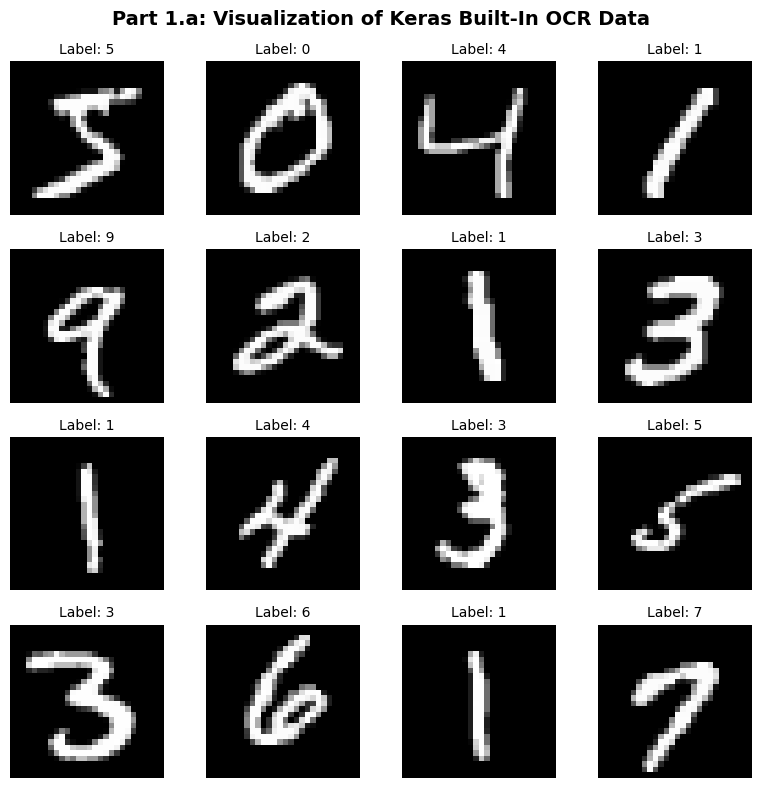

In [2]:
import matplotlib.pyplot as plt

# Setup the visualization canvas
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
fig.suptitle(
    "Part 1.a: Visualization of Keras Built-In OCR Data",
    fontsize=14,
    fontweight="bold",
)

for idx, ax in enumerate(axes.flat):
    ax.imshow(X_train[idx], cmap="gray")
    ax.axis("off")
    ax.set_title(f"Label: {y_train[idx]}", fontsize=10)

plt.tight_layout()
plt.show()

In [3]:
import numpy as np

# Normalize pixel values from integers [0, 255] to floats [0.0, 1.0]
X_train_norm = X_train.astype('float32') / 255
X_test_norm = X_test.astype('float32') / 255
print(X_train_norm.shape)
print(X_test_norm.shape)

# -------------------------------------------------------------
# Configuration A: Channels at the END (channels_last) -> DEFAULT
# Target Shape: (Batch_Size, Height, Width, Channels) -> (60000, 28, 28, 1)
# -------------------------------------------------------------
# np.expand_dims adds an axis at index -1 (the very end)
X_train_last = np.expand_dims(X_train_norm, axis=-1)
X_test_last = np.expand_dims(X_test_norm, axis=-1)

print("\n--- Channels Last Configuration ---")
print(f"Processed Train Shape: {X_train_last.shape}")

# -------------------------------------------------------------
# Configuration B: Channels at the BEGINNING (channels_first)
# Target Shape: (Batch_Size, Channels, Height, Width) -> (60000, 1, 28, 28)
# -------------------------------------------------------------
# np.expand_dims adds an axis at index 1 (right after batch size)
X_train_first = np.expand_dims(X_train_norm, axis=1)
X_test_first = np.expand_dims(X_test_norm, axis=1)

print("\n--- Channels First Configuration ---")
print(f"Processed Train Shape: {X_train_first.shape}")


(60000, 28, 28)
(10000, 28, 28)

--- Channels Last Configuration ---
Processed Train Shape: (60000, 28, 28, 1)

--- Channels First Configuration ---
Processed Train Shape: (60000, 1, 28, 28)


In [4]:
IMG_HEIGHT = 28
IMG_WIDTH = 28
IMG_CHANNELS = 1

model = tf.keras.models.Sequential([

    # Define the input shape explicitly using the Input layer
    tf.keras.layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS)),

    # First Block (32 Filters)
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    # Second Block (64 Filters)
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    # Flattening & Fully Connected Layer (512 nodes)
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(512, activation='relu'),

    # Output Layer (10 classes for digits 0-9)
    tf.keras.layers.Dense(10, activation='softmax')

])

# Define a standard schedule (e.g., Exponential Decay)
lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=1e-3,
    decay_steps=10000,
    decay_rate=0.9
)

# Compile the Model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Print the model architecture summary to check your work
model.summary()



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 10, 10, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 594,922 (2.27 MB)

 Trainable params: 594,922 (2.27 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
BATCH_SIZE = 128
EPOCHS = 20

history = model.fit(
    X_train_last,
    y_train,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=(X_test_last, y_test),
)

Epoch 1/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 26s 34ms/step - accuracy: 0.9549 - loss: 0.1487 - val_accuracy: 0.9856 - val_loss: 0.0449
Epoch 2/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - accuracy: 0.9885 - loss: 0.0383 - val_accuracy: 0.9919 - val_loss: 0.0255
Epoch 3/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9922 - loss: 0.0262 - val_accuracy: 0.9891 - val_loss: 0.0322
Epoch 4/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9934 - loss: 0.0208 - val_accuracy: 0.9923 - val_loss: 0.0227
Epoch 5/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9956 - loss: 0.0146 - val_accuracy: 0.9920 - val_loss: 0.0271
Epoch 6/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9960 - loss: 0.0124 - val_accuracy: 0.9922 - val_loss: 0.0249
Epoch 7/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9968 - loss: 0.0099 - val_accuracy: 0.9925 - val_loss: 0.0252
Epoch 8/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9969 - loss: 0.0096 - val_accuracy:

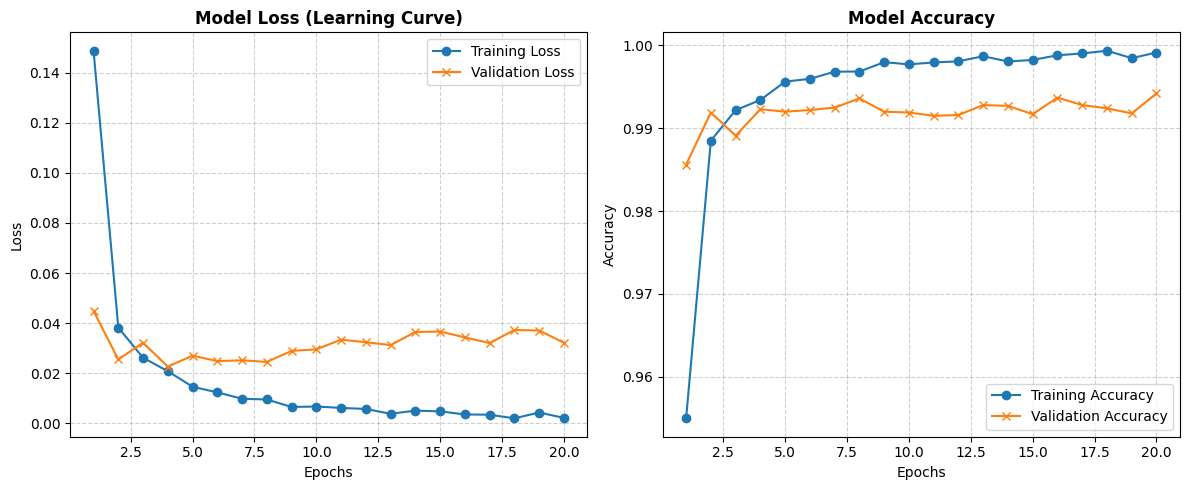

In [6]:
def plot_learning_curves(history, epochs):
    """Generates clean, side-by-side diagnostic plots for loss and accuracy

    across training and validation sets.
    """
    epochs_range = range(1, epochs + 1)
    plt.figure(figsize=(12, 5))

    # Panel 1: Loss Evaluation Curve
    plt.subplot(1, 2, 1)
    plt.plot(
        epochs_range, history.history["loss"], label="Training Loss", marker="o"
    )
    plt.plot(
        epochs_range,
        history.history["val_loss"],
        label="Validation Loss",
        marker="x",
    )
    plt.title("Model Loss (Learning Curve)", fontsize=12, fontweight="bold")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.6)

    # Panel 2: Accuracy Evaluation Curve
    plt.subplot(1, 2, 2)
    plt.plot(
        epochs_range,
        history.history["accuracy"],
        label="Training Accuracy",
        marker="o",
    )
    plt.plot(
        epochs_range,
        history.history["val_accuracy"],
        label="Validation Accuracy",
        marker="x",
    )
    plt.title("Model Accuracy", fontsize=12, fontweight="bold")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.6)

    plt.tight_layout()
    plt.show()


# Call your brand new visualization method
plot_learning_curves(history, EPOCHS)

In [7]:
(x_train_cifar, y_train_cifar), (x_test_cifar, y_test_cifar) = tf.keras.datasets.cifar10.load_data()
print(f"CIFAR-10 Training Data Shape: {x_train_cifar.shape}")

CIFAR-10 Training Data Shape: (50000, 32, 32, 3)


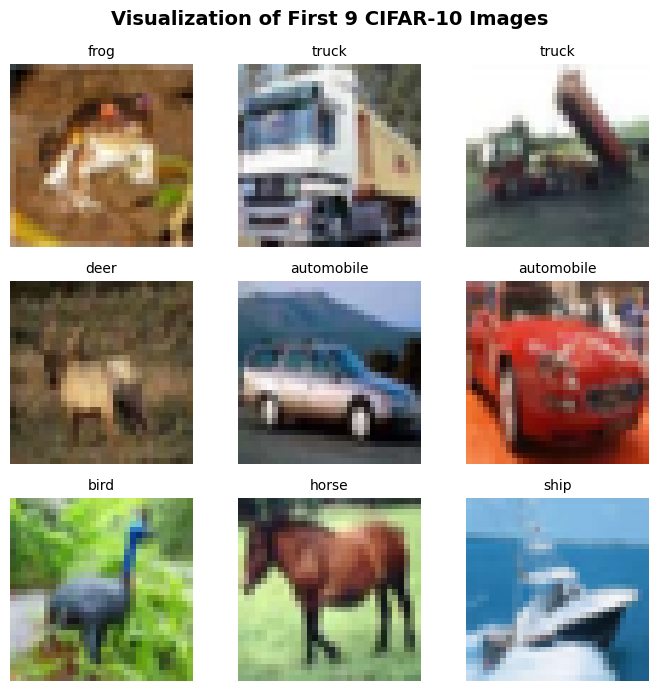

In [8]:
# Map the integer labels to their actual string class names
class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck",
]

fig, axes = plt.subplots(3, 3, figsize=(7, 7))
fig.suptitle(
    "Visualization of First 9 CIFAR-10 Images",
    fontsize=14,
    fontweight="bold",
)
for idx, ax in enumerate(axes.flat):
    # Display the colorful image array directly (no cmap='gray' needed here!)
    ax.imshow(x_train_cifar[idx], cmap="gray")
    ax.axis("off")

    # Fetch the class index and extract the corresponding text name
    class_idx = int(y_train_cifar[idx][0])
    ax.set_title(f"{class_names[class_idx]}", fontsize=10)

plt.tight_layout()
plt.show()

In [9]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

x_train_cifar_norm = x_train_cifar.astype(float) / 255
x_test_cifar_norm = x_test_cifar.astype(float) / 255

print(x_train_cifar_norm.shape)
print(x_test_cifar_norm.shape)

# Define the Augmentation Pipeline (Shear, Zoom, Horizontal Flip)
# Note: "seared" in your prompt is a common typo for a "shear" transformation
train_datagen = ImageDataGenerator(
    shear_range=0.2,  # Shear image by 20%
    zoom_range=0.2,  # Zoom image by 20%
    horizontal_flip=True,  # Randomly flip images horizontally
)

# Fit the generator to the training data
train_datagen.fit(x_train_cifar_norm)


(50000, 32, 32, 3)
(10000, 32, 32, 3)


In [10]:
# Design the Updated CNN Architecture

model_cifar = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(512, activation='relu'),
    tf.keras.layers.Dense(256, activation='relu'),

    tf.keras.layers.Dense(10, activation='softmax'),
])

# Define the decay math using a Keras 3 schedule
# This matches the legacy formula: lr = initial_lr / (1 + decay_rate * step)
lr_schedule = tf.keras.optimizers.schedules.InverseTimeDecay(
    initial_learning_rate=0.005,
    decay_steps=1,
    decay_rate=1e-6,
    staircase=False
)

# Pass the schedule and momentum into the standard Keras 3 SGD optimizer
opt = tf.keras.optimizers.SGD(
    learning_rate=lr_schedule,
    momentum=0.9
)

# Compile your model normally
model_cifar.compile(
    optimizer=opt,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [11]:

# Hyperparameters & Model Fitting
BATCH_SIZE = 128
EPOCHS = 20

# Use flow to stream real-time augmented image matrices during training - UPDATED TO model_cifar
history = model_cifar.fit(
    train_datagen.flow(x_train_cifar_norm, y_train_cifar, batch_size=BATCH_SIZE),
    epochs=EPOCHS,
    validation_data=(x_test_cifar_norm, y_test_cifar),
)



Epoch 1/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 53s 116ms/step - accuracy: 0.2628 - loss: 2.0142 - val_accuracy: 0.3170 - val_loss: 1.9620
Epoch 2/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 28s 71ms/step - accuracy: 0.4326 - loss: 1.5748 - val_accuracy: 0.4894 - val_loss: 1.4243
Epoch 3/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 28s 71ms/step - accuracy: 0.4864 - loss: 1.4273 - val_accuracy: 0.5177 - val_loss: 1.3227
Epoch 4/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 28s 71ms/step - accuracy: 0.5280 - loss: 1.3208 - val_accuracy: 0.5499 - val_loss: 1.2649
Epoch 5/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 28s 71ms/step - accuracy: 0.5586 - loss: 1.2421 - val_accuracy: 0.5777 - val_loss: 1.1888
Epoch 6/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 28s 70ms/step - accuracy: 0.5835 - loss: 1.1813 - val_accuracy: 0.5917 - val_loss: 1.1687
Epoch 7/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 28s 71ms/step - accuracy: 0.6028 - loss: 1.1276 - val_accuracy: 0.6217 - val_loss: 1.0831
Epoch 8/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 28s 71ms/step - accuracy: 0.6242 - loss: 1.0675 -

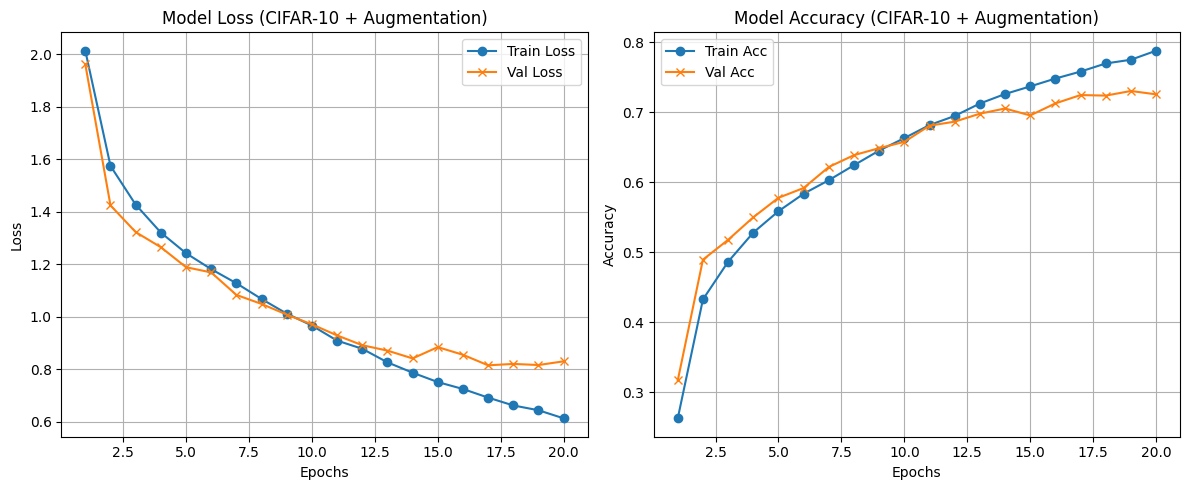

In [12]:
def plot_learning_curves(history, epochs, loss_title, accuracy_title):
    epochs_range = range(1, epochs + 1)
    plt.figure(figsize=(12, 5))

    # Loss Curve
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, history.history["loss"], label="Train Loss", marker="o")
    plt.plot(epochs_range, history.history["val_loss"], label="Val Loss", marker="x")
    plt.title(loss_title)
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)

    # Accuracy Curve
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, history.history["accuracy"], label="Train Acc", marker="o")
    plt.plot(epochs_range, history.history["val_accuracy"], label="Val Acc", marker="x")
    plt.title(accuracy_title)
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()


plot_learning_curves(history, EPOCHS, "Model Loss (CIFAR-10 + Augmentation)","Model Accuracy (CIFAR-10 + Augmentation)")

In [13]:
# Design 2 CNN Architecture with Batch Normalization

model_cifar_v2 = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.Conv2D(32, (3, 3), padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.Conv2D(64, (3, 3), padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(512),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),

    tf.keras.layers.Dense(256),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    # Softmax Class Predictions
    tf.keras.layers.Dense(10, activation='softmax'),
])

# Define the decay math using a Keras 3 schedule
# This matches the legacy formula: lr = initial_lr / (1 + decay_rate * step)
lr_schedule = tf.keras.optimizers.schedules.InverseTimeDecay(
    initial_learning_rate=0.005,
    decay_steps=1,
    decay_rate=1e-6,
    staircase=False
)

# Pass the schedule and momentum into the standard Keras 3 SGD optimizer
opt = tf.keras.optimizers.SGD(
    learning_rate=lr_schedule,
    momentum=0.9
)

# Compile your model normally
model_cifar_v2.compile(
    optimizer=opt,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Model Execution
BATCH_SIZE = 128
EPOCHS = 20

# Use flow to stream real-time augmented image matrices during training - UPDATED TO model_cifar
history_v2 = model_cifar_v2.fit(
    train_datagen.flow(x_train_cifar_norm, y_train_cifar, batch_size=BATCH_SIZE),
    epochs=EPOCHS,
    validation_data=(x_test_cifar_norm, y_test_cifar),
)


Epoch 1/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 54s 112ms/step - accuracy: 0.5101 - loss: 1.3719 - val_accuracy: 0.4668 - val_loss: 1.5097
Epoch 2/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 28s 70ms/step - accuracy: 0.6489 - loss: 0.9930 - val_accuracy: 0.6171 - val_loss: 1.0787
Epoch 3/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 28s 72ms/step - accuracy: 0.7083 - loss: 0.8279 - val_accuracy: 0.6801 - val_loss: 0.9472
Epoch 4/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 28s 72ms/step - accuracy: 0.7457 - loss: 0.7293 - val_accuracy: 0.6416 - val_loss: 1.0650
Epoch 5/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 28s 71ms/step - accuracy: 0.7705 - loss: 0.6578 - val_accuracy: 0.7268 - val_loss: 0.7820
Epoch 6/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 28s 71ms/step - accuracy: 0.7901 - loss: 0.6017 - val_accuracy: 0.7220 - val_loss: 0.8118
Epoch 7/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 30s 75ms/step - accuracy: 0.8061 - loss: 0.5564 - val_accuracy: 0.7342 - val_loss: 0.7856
Epoch 8/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 28s 71ms/step - accuracy: 0.8207 - loss: 0.5139 -

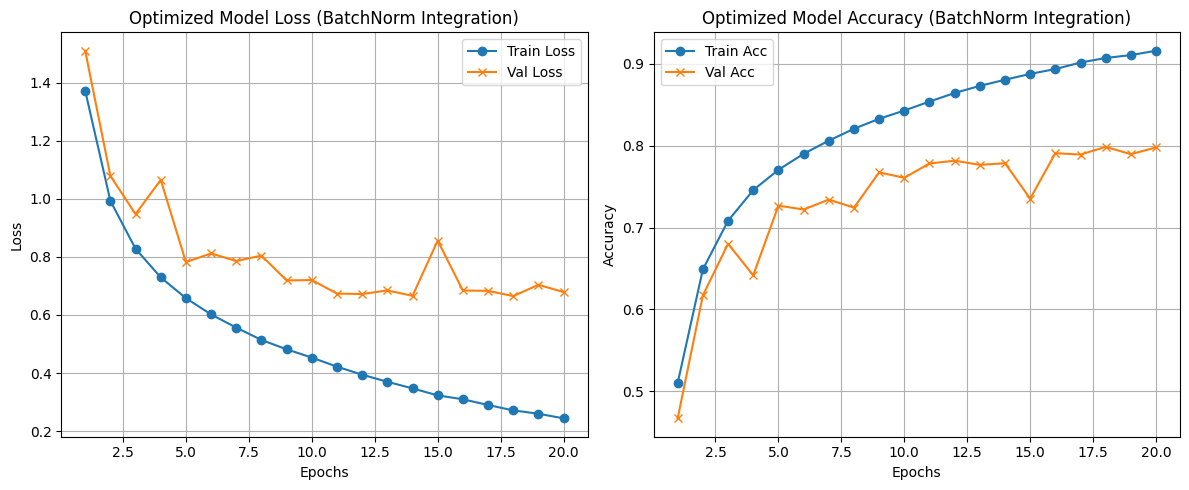

In [14]:
plot_learning_curves(history_v2, EPOCHS,"Optimized Model Loss (BatchNorm Integration)","Optimized Model Accuracy (BatchNorm Integration)")

In [15]:
import matplotlib.pyplot as plt
import tensorflow as tf

# 1. Load and Preprocess CIFAR-10 Data
(X_train_final, y_train_final), (X_test_final, y_test_final) = tf.keras.datasets.cifar10.load_data()
X_train_final = X_train_final.astype("float32") / 255.0
X_test_final = X_test_final.astype("float32") / 255.0

BATCH_SIZE = 128
EPOCHS = 10  # Pre-trained models converge very quickly; 10 epochs is standard for comparison


# 2. Reusable Function to Build Transfer Learning Models
def build_transfer_model(model_name):
    # Choose base pre-trained network with ImageNet weights
    if model_name == "VGG16":
        base_model = tf.keras.applications.VGG16(
            weights="imagenet", include_top=False, input_shape=(96, 96, 3)
        )
    elif model_name == "MobileNetV2":
        base_model = tf.keras.applications.MobileNetV2(
            weights="imagenet", include_top=False, input_shape=(96, 96, 3)
        )

    # Freeze the base model weights to preserve pre-trained knowledge
    base_model.trainable = False

    # Construct the Sequential Pipeline
    model = tf.keras.models.Sequential(
        [
            tf.keras.layers.Input(shape=(32, 32, 3)),
            # Resize 32x32 images to 96x96 so pre-trained filters work optimally
            tf.keras.layers.Resizing(96, 96),
            base_model,
            tf.keras.layers.GlobalAveragePooling2D(),
            tf.keras.layers.Dense(256, activation="relu"),
            tf.keras.layers.Dropout(0.3),  # Regularization
            tf.keras.layers.Dense(10, activation="softmax"),
        ]
    )

    model.compile(
        optimizer="adam",  # Using Adam for swift transfer learning convergence
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


# 3. Train Model 1: VGG16
print("\n--- Training VGG16 Transfer Learning Model ---")
vgg_model = build_transfer_model("VGG16")
vgg_history = vgg_model.fit(
    X_train_final,
    y_train_final,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_test_final, y_test_final),
)
vgg_eval = vgg_model.evaluate(X_test_final, y_test_final, verbose=0)





--- Training VGG16 Transfer Learning Model ---
Epoch 1/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 78s 159ms/step - accuracy: 0.5329 - loss: 1.3580 - val_accuracy: 0.6297 - val_loss: 1.0833
Epoch 2/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 47s 121ms/step - accuracy: 0.6335 - loss: 1.0558 - val_accuracy: 0.6516 - val_loss: 0.9978
Epoch 3/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 52s 133ms/step - accuracy: 0.6582 - loss: 0.9850 - val_accuracy: 0.6714 - val_loss: 0.9535
Epoch 4/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 50s 129ms/step - accuracy: 0.6722 - loss: 0.9401 - val_accuracy: 0.6775 - val_loss: 0.9246
Epoch 5/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 51s 130ms/step - accuracy: 0.6846 - loss: 0.9084 - val_accuracy: 0.6859 - val_loss: 0.8981
Epoch 6/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 51s 129ms/step - accuracy: 0.6930 - loss: 0.8863 - val_accuracy: 0.6909 - val_loss: 0.8882
Epoch 7/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 51s 131ms/step - accuracy: 0.6978 - loss: 0.8665 - val_accuracy: 0.6926 - val_loss: 0.8870
Epoch 8/10
391/391 ━━━━━━━━━━━━━━━━

In [16]:
# 4. Train Model 2: MobileNetV2
print("\n--- Training MobileNetV2 Transfer Learning Model ---")
mobilenet_model = build_transfer_model("MobileNetV2")
mobilenet_history = mobilenet_model.fit(
    X_train_final,
    y_train_final,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_test_final, y_test_final),
)
mobilenet_eval = mobilenet_model.evaluate(X_test_final, y_test_final, verbose=0)



--- Training MobileNetV2 Transfer Learning Model ---
Epoch 1/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 69s 119ms/step - accuracy: 0.7241 - loss: 0.8013 - val_accuracy: 0.7932 - val_loss: 0.5942
Epoch 2/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - accuracy: 0.7900 - loss: 0.5988 - val_accuracy: 0.8033 - val_loss: 0.5591
Epoch 3/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - accuracy: 0.8094 - loss: 0.5397 - val_accuracy: 0.8088 - val_loss: 0.5364
Epoch 4/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - accuracy: 0.8248 - loss: 0.4995 - val_accuracy: 0.8165 - val_loss: 0.5278
Epoch 5/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - accuracy: 0.8368 - loss: 0.4616 - val_accuracy: 0.8193 - val_loss: 0.5312
Epoch 6/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - accuracy: 0.8443 - loss: 0.4367 - val_accuracy: 0.8164 - val_loss: 0.5335
Epoch 7/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - accuracy: 0.8534 - loss: 0.4111 - val_accuracy: 0.8216 - val_loss: 0.5235
Epoch 8/10
391/391 ━━━━━━━━━━━━━━━━


================ TEST ACCURACY COMPARISON ================
VGG16       : 69.79%
MobileNetV2 : 82.16%


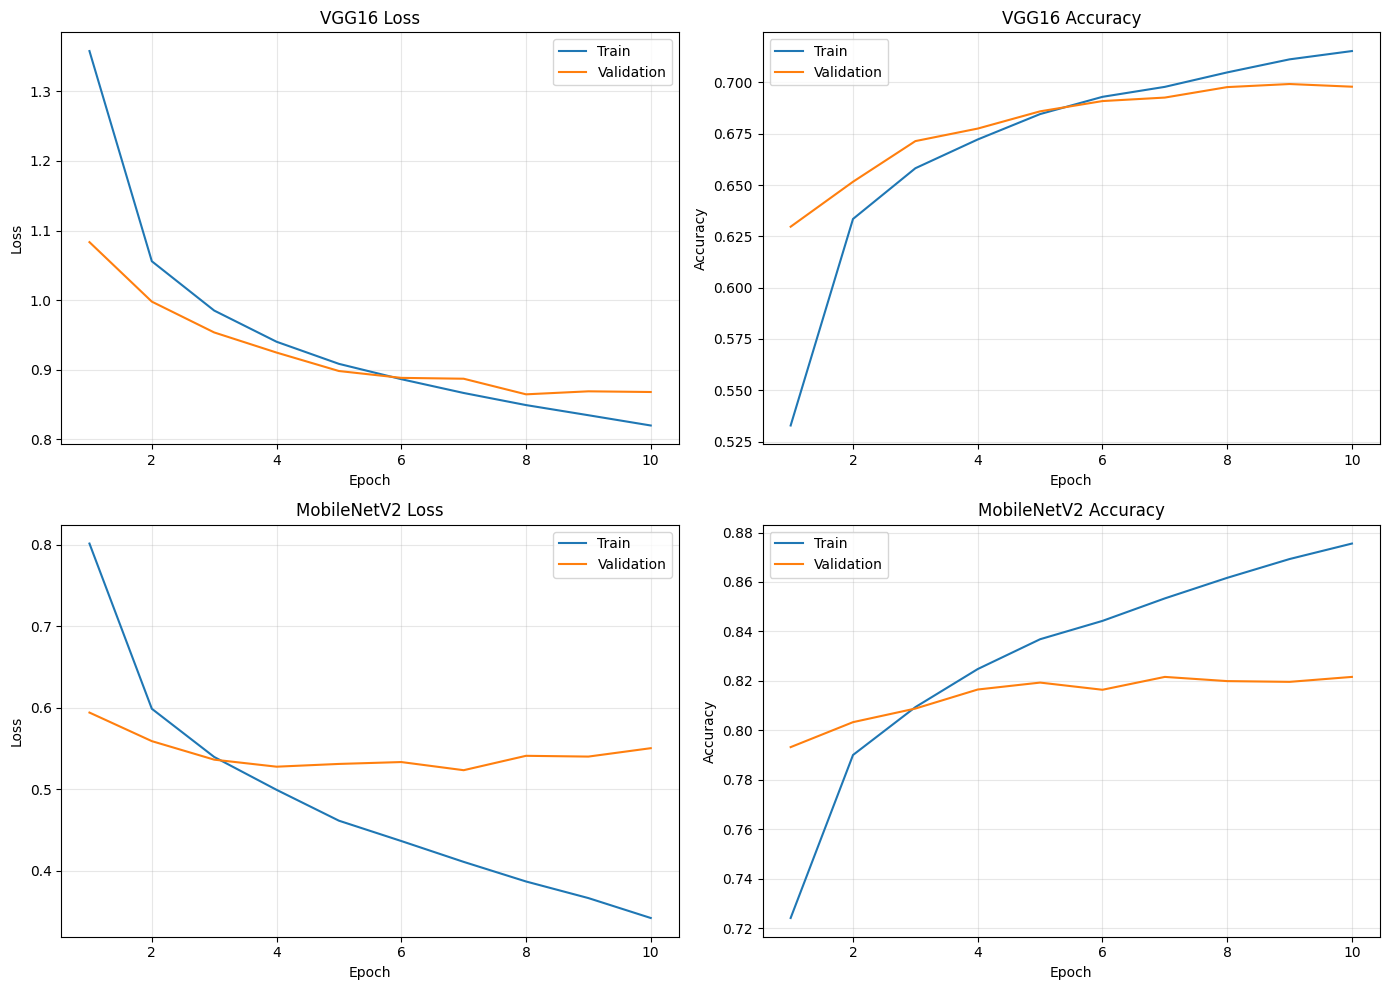

In [19]:
# Compare test accuracy and learning curves for both pretrained models
print("\n================ TEST ACCURACY COMPARISON ================")
print(f"VGG16       : {vgg_eval[1] * 100:.2f}%")
print(f"MobileNetV2 : {mobilenet_eval[1] * 100:.2f}%")
print("==========================================================")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
vgg_epochs = range(1, len(vgg_history.history["loss"]) + 1)
mobile_epochs = range(1, len(mobilenet_history.history["loss"]) + 1)

axes[0, 0].plot(vgg_epochs, vgg_history.history["loss"], label="Train")
axes[0, 0].plot(vgg_epochs, vgg_history.history["val_loss"], label="Validation")
axes[0, 0].set_title("VGG16 Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(vgg_epochs, vgg_history.history["accuracy"], label="Train")
axes[0, 1].plot(vgg_epochs, vgg_history.history["val_accuracy"], label="Validation")
axes[0, 1].set_title("VGG16 Accuracy")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Accuracy")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].plot(mobile_epochs, mobilenet_history.history["loss"], label="Train")
axes[1, 0].plot(mobile_epochs, mobilenet_history.history["val_loss"], label="Validation")
axes[1, 0].set_title("MobileNetV2 Loss")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Loss")
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(mobile_epochs, mobilenet_history.history["accuracy"], label="Train")
axes[1, 1].plot(mobile_epochs, mobilenet_history.history["val_accuracy"], label="Validation")
axes[1, 1].set_title("MobileNetV2 Accuracy")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Accuracy")
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Assignment 2.1 — CNN and Pre-Trained Models
Purpose: Build a CNN for handwritten-digit OCR using MNIST, train a CNN on CIFAR-10 with image augmentation, improve generalization, and compare two ImageNet-pretrained models using transfer learning.

How to use this notebook

Run the cells from top to bottom in order.
The first run may download MNIST, CIFAR-10, and ImageNet weights for VGG16 and MobileNetV2.
Training cells can take time, especially the pretrained VGG16 model.
Outputs have been cleared because the training/evaluation workflow was revised. Re-run the notebook to generate fresh curves and final test metrics.
Important evaluation practice: A validation subset is separated from the training data. The test set is held back for final evaluation only, rather than being repeatedly used to guide training.

Cell 1 — Imports, random seed, and MNIST loading
This cell imports the main libraries, sets random seeds to make results more reproducible, and loads MNIST from TensorFlow/Keras. MNIST contains grayscale images of handwritten digits from 0 to 9. The printed shapes confirm the number of images and their dimensions.

Cell 2 — Visualize MNIST (Part 1.a)
This cell displays a 4 × 4 sample of handwritten digits. The grayscale colormap is appropriate because MNIST images contain one intensity channel. The label above each image is the correct target class. This visual check helps confirm that the dataset loaded correctly.

Cell 3 — Normalize and reshape MNIST
Neural networks train more reliably when pixel values are scaled to a small numeric range. Dividing by 255 converts pixels from 0–255 to 0–1. The extra final dimension changes each image from 28 × 28 to 28 × 28 × 1, which is the channels-last input format expected by the CNN's Conv2D layers.

Cell 4 — Build the MNIST CNN (Part 1.b)
The network has exactly four convolution layers: two with 32 filters and two with 64 filters. Max-pooling reduces the spatial dimensions. Flatten converts the feature maps into a vector, followed by the required 512-unit hidden dense layer and a 10-unit softmax output for digit classes. Sparse categorical cross-entropy is suitable because labels are integer class IDs.

Cell 5 — Train and test the MNIST CNN
The model is trained for 20 epochs with batch size 128, as requested. Ten percent of the training data is used for validation. The separate 10,000-image test set is evaluated only after training, providing a final estimate of performance on unseen data.

Cell 6 — MNIST learning curves and interpretation
The loss curves show prediction error; lower is better. Accuracy curves show the fraction of correctly classified images; higher is better. If training and validation curves improve together and remain close, the model is generalizing. If training improves while validation stalls or worsens, the model is likely overfitting. Use the actual plotted curves and test accuracy when writing the final observation.

Cell 7 — Load CIFAR-10
This cell loads CIFAR-10, which has 50,000 training and 10,000 test images. Unlike MNIST, each image is a 32 × 32 RGB color image with three channels. The labels are integer IDs for ten object categories.

Cell 8 — Visualize the first nine CIFAR-10 images (Part 2.a)
The class-name list maps each integer label to a readable category. The 3 × 3 plot displays the first nine color images and their labels. This is a quick visual check of image content, color channels, and label mapping.

Cell 9 — Normalize and augment CIFAR-10 (Part 2.b)
Pixel values are scaled to 0–1. The training generator applies the requested 20% shear, 20% zoom, and random horizontal flip, creating varied versions of training images. A separate, unaugmented validation subset is used to monitor generalization. The test set is not used for training or model selection.

Cell 10 — Build the baseline CIFAR-10 CNN (Part 2.b)
This architecture follows the assignment: four convolution layers with 32, 32, 64, and 64 filters, then dense hidden layers of 512 and 256 units, and a 10-class softmax output. SGD uses learning rate 0.005, decay 1 × 10⁻⁶, and momentum 0.9. In current Keras, InverseTimeDecay expresses the legacy inverse-time decay schedule.

Cell 11 — Train the baseline CIFAR-10 CNN
The model learns from augmented batches of images. It runs for 20 epochs with batch size 128. Validation metrics are calculated on the held-out, unaugmented validation subset. The final test accuracy is calculated separately after fitting.

Cell 12 — Baseline CIFAR-10 learning curves
These plots compare training and validation loss/accuracy over the epochs. Look for a widening gap: high training accuracy with lower or stagnant validation accuracy, especially alongside rising validation loss, is evidence of overfitting. This observation motivates Part 2.c.

Cell 13 — Part 2.c: Improve generalization
This model adds Batch Normalization, Dropout, and L2 weight regularization while keeping the four-convolution-layer pattern. Batch Normalization stabilizes intermediate activations. Dropout randomly disables a fraction of units during training, and L2 discourages excessively large weights. Early Stopping restores the weights from the best validation-loss epoch. These are regularization techniques intended to reduce overfitting; compare the resulting curves and test score with the baseline rather than assuming improvement.

Cell 14 — Evaluate the improved CNN
The learning curves show whether the added regularization narrows the training/validation gap. The printed baseline and improved test accuracies provide a direct comparison on the same held-out test set. A higher test score and a smaller generalization gap would support the recommendation.

Cell 15 — Part 2.d: Build and train VGG16 transfer learning
VGG16 is initialized with ImageNet weights and its convolutional base is frozen. CIFAR-10 images are resized from 32 × 32 to 96 × 96, then passed through VGG16's own preprocessing function. A new pooling and dense classification head is trained for the ten CIFAR-10 classes. The validation split comes from the training data; test accuracy is measured only after fitting.

Cell 16 — Train MobileNetV2 transfer learning
MobileNetV2 is a second ImageNet-pretrained feature extractor. It uses its own preprocessing function, which is different from VGG16's preprocessing. The same training/validation/test protocol and classification head are used to make the comparison more meaningful.

Cell 17 — Compare pretrained models (Part 2.d)
The printed test accuracies answer the assignment's test-accuracy question. The four plots show training and validation loss/accuracy for both models. Compare final test accuracy, convergence speed, and the gap between training and validation curves. The higher test accuracy is the stronger result on this run; also consider model size and training/inference cost when discussing trade-offs.

Written observations to complete after running the notebook
Part 1.b — MNIST learning curve
Record the final training accuracy, validation accuracy, and test accuracy. Explain whether training and validation loss decrease together. If training accuracy is higher than validation accuracy, comment on the size of the gap and whether it suggests overfitting.

Part 2.b — CIFAR-10 baseline learning curve
Describe whether the model continues improving on validation data throughout the 20 epochs. If training accuracy increases while validation accuracy plateaus, or validation loss begins increasing, identify this as overfitting / limited generalization.

Part 2.c — Recommended technique
The implemented recommendation combines Batch Normalization, Dropout, L2 regularization, and Early Stopping. Compare the baseline and improved models using their held-out test accuracies and validation curves. State whether the changes helped in this run; do not claim improvement unless the measured results support it.

Part 2.d — Pretrained-model comparison
Report the VGG16 and MobileNetV2 test accuracies from the final comparison cell. Identify which performed better on this run and compare their learning curves. Note that both use frozen ImageNet feature extractors and newly trained CIFAR-10 classification heads.

Final submission checklist
  * MNIST sample visualization included.
 * MNIST CNN has four convolution layers (32, 32, 64, 64) and one 512-unit hidden dense layer.
 * MNIST learning curves and written interpretation completed.
 * CIFAR-10 first-nine image visualization included.
 * CIFAR-10 training augmentation uses shear 0.2, zoom 0.2, and horizontal flip.
 * CIFAR-10 baseline CNN has four convolution layers and dense layers of 512 and 256 units.
 * SGD configuration is 0.005 learning rate, 1e-6 decay, and 0.9 momentum.
 Baseline learning curves and interpretation completed.
 * Part 2.c improvement is trained and compared against the baseline.
 * At least two pretrained models are trained, their learning curves are plotted, and their test accuracies are compared.
 * All cells have been run successfully and the saved notebook contains fresh outputs.

